In [1]:
# !pip install pandas scikit-learn matplotlib wordcloud openpyxl

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)


In [25]:
# PATH_DATA = r"C:\Users\User\OneDrive\Documents\praktikum_sentimen_kualitas air\fya monika_Test4_Analisis Sentimen.csv.csv"
PATH_DATA = None

ALIAS_KOLOM = {
    "created_at": ["created_at", "created at", "date", "tanggal", "waktu", "time", "timestamp", "datetime"],
    "username": ["username", "user_name", "user", "screen_name", "nama", "author", "name"],
    "full_text": ["full_text", "text", "tweet", "content", "isi", "komentar", "comment", "teks", "isi_tweet"],
}

def baca_file(path):
    if str(path).lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(path)
    for enc in ("utf-8-sig", "utf-8", "latin-1"):
        try:
            return pd.read_csv(path, sep=None, engine="python", encoding=enc)  # deteksi pemisah otomatis
        except UnicodeDecodeError:
            continue
    raise ValueError("File tidak dapat dibaca.")

if PATH_DATA:
    SUMBER = PATH_DATA
    SUMBER = "tweet_data.csv"
else:
    SUMBER = "tweet_data.xlsx"

df = baca_file(SUMBER)
df.columns = [str(c).strip() for c in df.columns]
peta = {}
for target, alias in ALIAS_KOLOM.items():
    for c in df.columns:
        if c.lower() in alias:
            peta[c] = target
            break
df = df.rename(columns=peta)
if "full_text" not in df.columns:
    raise ValueError(f"Kolom isi tweet tidak ditemukan. Kolom yang terbaca: {list(df.columns)}")
if "username" not in df.columns:
    df["username"] = "tidak_diketahui"
if "created_at" not in df.columns:
    df["created_at"] = pd.NaT
df = df[["created_at", "username", "full_text"]].dropna(subset=["full_text"]).copy()
df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")
print("Sumber data :", SUMBER)
print("Jumlah baris:", len(df))
df.head()

Sumber data : tweet_data.xlsx
Jumlah baris: 1200


,created_at,username,full_text
0,2026-01-01 06:06:05,maya641,"Air PDAM Singkawang kadang berasa aneh, tapi P..."
1,2026-01-01 20:58:31,hendra_pnk,"Sungai di Balikpapan tercemar limbah pabrik, i..."
2,2026-01-02 05:31:52,fajar594,Bagus banget inovasi pengolahan air bersih dar...
3,2026-01-02 14:27:16,tika,Info: PDAM Tirta Khatulistiwa akan melakukan p...
4,2026-01-03 06:06:35,dita_pnk,"Sungai di Palembang tercemar limbah pabrik, ik..."


In [26]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)   # URL
    text = re.sub(r"@\w+", " ", text)                    # mention
    text = re.sub(r"#\w+", " ", text)                    # hashtag
    text = re.sub(r"\bRT\b", " ", text)                  # tanda retweet
    text = text.lower()                                  # case folding
    text = re.sub(r"[^a-z\s]", " ", text)                # simbol & angka
    text = re.sub(r"\s+", " ", text).strip()             # spasi berlebih
    return text

KAMUS_SLANG = {
    "gak": "tidak", "ga": "tidak", "nggak": "tidak", "ngga": "tidak", "enggak": "tidak",
    "engga": "tidak", "tdk": "tidak", "gk": "tidak", "tak": "tidak",
    "udah": "sudah", "udh": "sudah", "sdh": "sudah", "dah": "sudah",
    "yg": "yang", "dgn": "dengan", "dg": "dengan", "utk": "untuk", "untk": "untuk",
    "tp": "tapi", "krn": "karena", "karna": "karena", "krna": "karena",
    "bgt": "sekali", "banget": "sekali", "bngt": "sekali", "jg": "juga", "jga": "juga",
    "sy": "saya", "gue": "saya", "gw": "saya", "aku": "saya", "aja": "saja", "doang": "saja",
    "emg": "memang", "emang": "memang", "blm": "belum", "belom": "belum",
    "lg": "lagi", "lgi": "lagi", "skrg": "sekarang", "skrang": "sekarang",
    "bs": "bisa", "bsa": "bisa", "hrs": "harus", "org": "orang", "orng": "orang",
    "kmrn": "kemarin", "kalo": "kalau", "klo": "kalau", "kl": "kalau",
    "dr": "dari", "pd": "pada", "mlm": "malam", "sm": "sama", "rmh": "rumah",
    "makasih": "terima kasih", "terimakasih": "terima kasih", "trims": "terima kasih",
    "thanks": "terima kasih", "thx": "terima kasih", "tq": "terima kasih", "tks": "terima kasih",
    "bgmn": "bagaimana", "gmn": "bagaimana", "gimana": "bagaimana",
    "tlg": "tolong", "plis": "tolong", "pls": "tolong", "mohon2": "mohon",
    # kata khusus topik air / PDAM
    "kran": "keran", "krn2": "karena", "ngeluh": "mengeluh", "keluhkan": "mengeluh",
    "kesal": "kesel", "cemar": "tercemar", "bgs": "bagus", "bgus": "bagus", "mantab": "mantap",
    "jlk": "jelek", "alhamdulilah": "alhamdulillah", "syukur": "syukurlah",
    "bnyk": "banyak", "byk": "banyak", "msh": "masih", "lbh": "lebih", "krg": "kurang",
    "knp": "kenapa", "brp": "berapa", "dlm": "dalam", "kpd": "kepada", "sbg": "sebagai",
    "tsb": "tersebut", "dll": "dan lain lain", "dsb": "dan sebagainya", "iya": "ya",
}


def normalisasi_text(text: str) -> str:
    """Normalisasi: huruf berulang (keruuuh -> keruh) dan kata tidak baku/singkatan -> baku."""
    text = re.sub(r"(.)\1{2,}", r"\1", text)
    kata = [KAMUS_SLANG.get(k, k) for k in text.split()]
    return re.sub(r"\s+", " ", " ".join(kata)).strip()

df["clean_text"] = df["full_text"].apply(clean_text)          # cleansing
df["normal_text"] = df["clean_text"].apply(normalisasi_text)  # normalisasi
df = df[df["normal_text"].str.len() > 0].drop_duplicates(subset="normal_text").reset_index(drop=True)
print("Jumlah data setelah cleansing, normalisasi & hapus duplikat:", len(df))
df[["full_text", "clean_text", "normal_text"]].head()

Jumlah data setelah cleansing, normalisasi & hapus duplikat: 957


,full_text,clean_text,normal_text
0,"Air PDAM Singkawang kadang berasa aneh, tapi P...",air pdam singkawang kadang berasa aneh tapi pa...,air pdam singkawang kadang berasa aneh tapi pa...
1,"Sungai di Balikpapan tercemar limbah pabrik, i...",sungai di balikpapan tercemar limbah pabrik ik...,sungai di balikpapan tercemar limbah pabrik ik...
2,Bagus banget inovasi pengolahan air bersih dar...,bagus banget inovasi pengolahan air bersih dar...,bagus sekali inovasi pengolahan air bersih dar...
3,Info: PDAM Tirta Khatulistiwa akan melakukan p...,info pdam tirta khatulistiwa akan melakukan pe...,info pdam tirta khatulistiwa akan melakukan pe...
4,"Sungai di Palembang tercemar limbah pabrik, ik...",sungai di palembang tercemar limbah pabrik ika...,sungai di palembang tercemar limbah pabrik ika...


In [27]:
berubah = df[df["clean_text"] != df["normal_text"]]
print(f"{len(berubah)} dari {len(df)} tweet berubah pada tahap normalisasi")
display(berubah[["clean_text", "normal_text"]].rename(
    columns={"clean_text": "sebelum normalisasi", "normal_text": "sesudah normalisasi"}).head(10))

# Contoh khusus kata gaul/tidak baku
contoh = ["Air PDAM keruuuh bgt, bau lagi!! @pdam #airkotor https://t.co/x",
          "makasih yaa petugas, air udah jernih lg"]
display(pd.DataFrame({"sebelum": contoh,
                      "sesudah cleansing": [clean_text(t) for t in contoh],
                      "sesudah normalisasi": [normalisasi_text(clean_text(t)) for t in contoh]}))

# ===== SIMPAN DATA NORMALISASI =====
df[["created_at", "username", "full_text", "clean_text", "normal_text"]].rename(
    columns={"clean_text": "teks_cleansing", "normal_text": "teks_normalisasi"}
).to_csv("data_normalisasi.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(list(KAMUS_SLANG.items()), columns=["kata_tidak_baku", "kata_baku"]).to_csv(
    "kualitas air_normalisasi.csv", index=False, encoding="utf-8-sig")
print("Tersimpan: data_normalisasi.csv & kualitas air_normalisasi.csv")

137 dari 957 tweet berubah pada tahap normalisasi


,sebelum normalisasi,sesudah normalisasi
2,bagus banget inovasi pengolahan air bersih dar...,bagus sekali inovasi pengolahan air bersih dar...
21,kulit gatal dan iritasi setelah mandi pakai ai...,kulit gatal dan iritasi setelah mandi pakai ai...
36,sudah hari air keran di rumah berasa aneh paly...,sudah hari air keran di rumah berasa aneh paly...
40,bagus banget inovasi pengolahan air bersih dar...,bagus sekali inovasi pengolahan air bersih dar...
43,senang sekali air sumur di rumah sudah bening ...,senang sekali air sumur di rumah sudah bening ...
45,senang sekali air sumur di rumah sudah segar s...,senang sekali air sumur di rumah sudah segar s...
46,pdam air mengalir berbau kaporit lagi sudah ru...,pdam air mengalir berbau kaporit lagi sudah ru...
47,air isi ulang langganan saya segar dan layak m...,air isi ulang langganan saya segar dan layak m...
49,sudah hari air keran di rumah tercemar pam jay...,sudah hari air keran di rumah tercemar pam jay...
52,sudah hari air keran di rumah berbau kaporit p...,sudah hari air keran di rumah berbau kaporit p...


,sebelum,sesudah cleansing,sesudah normalisasi
0,"Air PDAM keruuuh bgt, bau lagi!! @pdam #airkot...",air pdam keruuuh bgt bau lagi,air pdam keruh sekali bau lagi
1,"makasih yaa petugas, air udah jernih lg",makasih yaa petugas air udah jernih lg,terima kasih yaa petugas air sudah jernih lagi


Tersimpan: data_normalisasi.csv & kualitas air_normalisasi.csv


In [28]:
KATA_POSITIF = {
    "aman", "lega", "selamat", "bantuan", "pulih", "jernih", "bersih", "segar", "layak", "bening", "sehat",
    "lancar", "bagus", "mantap", "membaik", "baik", "sukses", "berhasil", "puas", "senang", "bahagia",
    "terima kasih", "alhamdulillah", "syukurlah", "rekomendasi", "apresiasi", "bangga", "nyaman",
    "membantu", "terjaga", "memenuhi", "tersertifikasi", "inovasi",
}
KATA_NEGATIF = {
    "keruh", "bau", "berbau", "kotor", "tercemar", "pencemaran", "parah", "rusak", "bahaya", "berbahaya",
    "limbah", "gatal", "diare", "buruk", "kecewa", "mengecewakan", "kesel", "resah", "krisis", "susah",
    "bocor", "mengeluh", "bakteri", "asam", "asin", "berbusa", "berlumpur", "jelek", "mengkhawatirkan",
    "memprihatinkan", "iritasi", "mati", "sulit", "kesulitan",
}
STOPWORD = {
    "yang", "di", "ke", "dan", "dari", "untuk", "dengan", "ini", "itu", "pada",
    "adalah", "atau", "juga", "karena", "akan", "ada", "tidak", "sudah", "saya",
    "kami", "kita", "mereka", "dalam", "oleh", "bisa", "udah", "nya", "aja",
    "yg", "dgn", "utk", "tp", "sih", "lah", "kok", "ya", "kan", "rt", "amp",
    "para", "sebagai", "lagi", "masih", "banget", "gak", "nggak", "ga", "tapi",
    "kalau", "jadi", "dong", "mau", "hari", "air", "sekali", "saja",
}

def hitung_kata(clean, kamus):
    return sum(len(re.findall(rf"\b{re.escape(k)}\b", clean)) for k in kamus)

def label_sentimen(clean):
    pos, neg = hitung_kata(clean, KATA_POSITIF), hitung_kata(clean, KATA_NEGATIF)
    if pos > neg:
        return "positif"
    if neg > pos:
        return "negatif"
    return "netral"

df["sentimen"] = df["normal_text"].apply(label_sentimen)

# Simpan data akhir beserta label sentimen
df[["created_at", "username", "full_text", "clean_text", "normal_text", "sentimen"]].rename(
    columns={"clean_text": "teks_cleansing", "normal_text": "teks_normalisasi"}
).to_csv("data_normalisasi_berlabel.csv", index=False, encoding="utf-8-sig")
print("Tersimpan: data_normalisasi_berlabel.csv")
df[["normal_text", "sentimen"]].head(10)

Tersimpan: data_normalisasi_berlabel.csv


,normal_text,sentimen
0,air pdam singkawang kadang berasa aneh tapi pa...,positif
1,sungai di balikpapan tercemar limbah pabrik ik...,negatif
2,bagus sekali inovasi pengolahan air bersih dar...,positif
3,info pdam tirta khatulistiwa akan melakukan pe...,netral
4,sungai di palembang tercemar limbah pabrik ika...,negatif
5,warga kubu raya resah air sungai berwarna cokl...,negatif
6,alhamdulillah air pdam di depok sekarang aman ...,positif
7,program bantuan filter air bersih untuk warga ...,positif
8,air keran di rumah sekarang tidak berbau dan s...,positif
9,air bersih makin susah yang ada cuma air berba...,negatif


sentimen
positif    412
netral     173
negatif    372
Name: count, dtype: int64


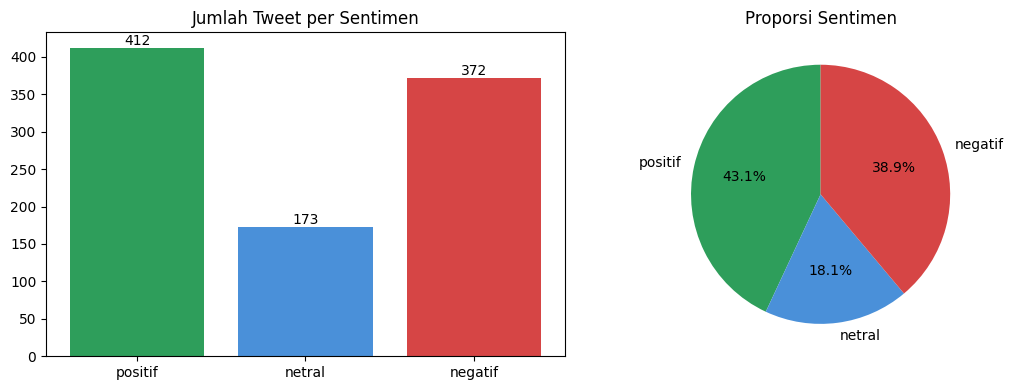

In [29]:
LABEL_ORDER = ["positif", "netral", "negatif"]
WARNA = {"positif": "#2e9e5b", "netral": "#4a90d9", "negatif": "#d64545"}

dist = df["sentimen"].value_counts().reindex(LABEL_ORDER).fillna(0).astype(int)
print(dist)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bars = axes[0].bar(dist.index, dist.values, color=[WARNA[l] for l in dist.index])
axes[0].bar_label(bars)
axes[0].set_title("Jumlah Tweet per Sentimen")
axes[1].pie(dist.values, labels=dist.index, colors=[WARNA[l] for l in dist.index],
            autopct="%1.1f%%", startangle=90)
axes[1].set_title("Proporsi Sentimen")
plt.tight_layout()
plt.show()

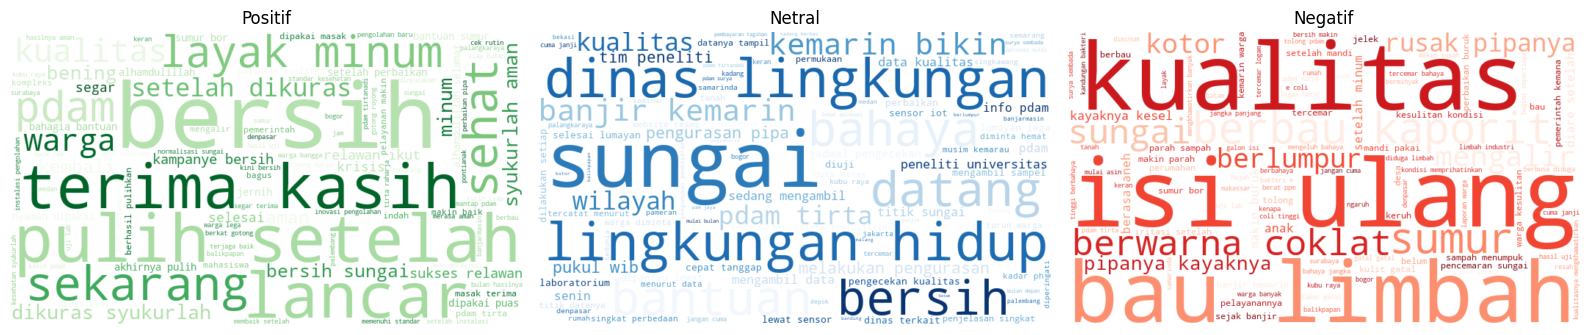

In [30]:
CMAP = {"positif": "Greens", "netral": "Blues", "negatif": "Reds"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, lab in zip(axes, LABEL_ORDER):
    teks = " ".join(df.loc[df["sentimen"] == lab, "normal_text"])
    ax.set_title(lab.capitalize())
    ax.axis("off")
    if teks.strip():
        wc = WordCloud(width=700, height=400, background_color="white", colormap=CMAP[lab],
                       stopwords=STOPWORD, max_words=100).generate(teks)
        ax.imshow(wc, interpolation="bilinear")
plt.tight_layout()
plt.show()

In [31]:
X, y = df["normal_text"], df["sentimen"]
strat = y if y.value_counts().min() >= 2 else None
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=strat)

vec = TfidfVectorizer(ngram_range=(1, 2), stop_words=list(STOPWORD))
Xtr = vec.fit_transform(X_train)
Xte = vec.transform(X_test)

model = MLPClassifier(hidden_layer_sizes=(100,), activation="relu", solver="adam",
                      max_iter=300, random_state=42)
model.fit(Xtr, y_train)
y_pred = model.predict(Xte)
print(f"Data latih: {len(X_train)} | Data uji: {len(X_test)}")

Data latih: 765 | Data uji: 192


In [32]:
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)

In [33]:
labels_ada = [l for l in LABEL_ORDER if l in set(y)]
p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)

ringkas = pd.DataFrame({
    "Metrik": ["Akurasi", "Presisi (weighted)", "Recall (weighted)", "F1-Score (weighted)"],
    "Nilai": [accuracy_score(y_test, y_pred), p, r, f]}).round(4)
display(ringkas)

print("Laporan per kelas:")
display(pd.DataFrame(classification_report(
    y_test, y_pred, labels=labels_ada, output_dict=True, zero_division=0)).T.round(3))

,Metrik,Nilai
0,Akurasi,0.9948
1,Presisi (weighted),0.9949
2,Recall (weighted),0.9948
3,F1-Score (weighted),0.9948


Laporan per kelas:


,precision,recall,f1-score,support
positif,0.988,1.000,0.994,83.000
netral,1.000,0.971,0.986,35.000
negatif,1.000,1.000,1.000,74.000
accuracy,0.995,0.995,0.995,0.995
macro avg,0.996,0.990,0.993,192.000
weighted avg,0.995,0.995,0.995,192.000


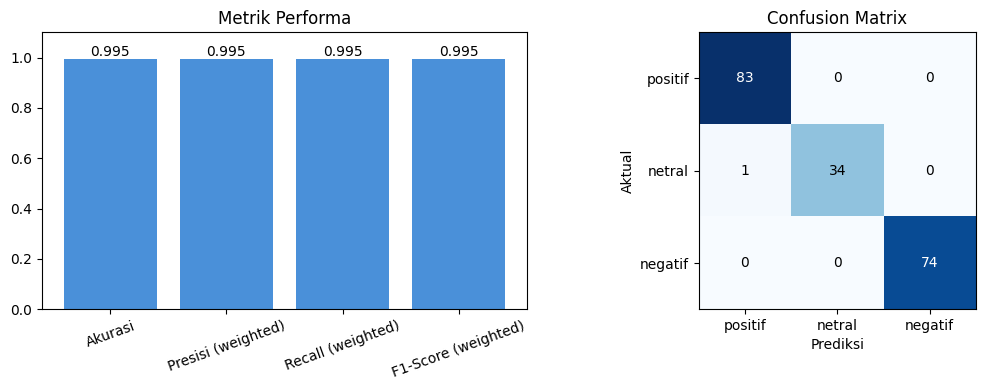

In [34]:
cm = confusion_matrix(y_test, y_pred, labels=labels_ada)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bars = axes[0].bar(ringkas["Metrik"], ringkas["Nilai"], color="#4a90d9")
axes[0].bar_label(bars, fmt="%.3f")
axes[0].set_ylim(0, 1.1)
axes[0].set_title("Metrik Performa")
axes[0].tick_params(axis="x", rotation=20)

im = axes[1].imshow(cm, cmap="Blues")
axes[1].set_xticks(range(len(labels_ada)), labels_ada)
axes[1].set_yticks(range(len(labels_ada)), labels_ada)
axes[1].set_xlabel("Prediksi")
axes[1].set_ylabel("Aktual")
axes[1].set_title("Confusion Matrix")
for i in range(len(labels_ada)):
    for j in range(len(labels_ada)):
        axes[1].text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()

In [35]:
EMOJI = {"positif": "😊", "netral": "😐", "negatif": "😠"}

def prediksi(teks):
    dibersihkan = clean_text(teks)
    bersih = normalisasi_text(dibersihkan)
    proba = model.predict_proba(vec.transform([bersih]))[0]
    hasil = model.classes_[int(np.argmax(proba))]
    print(f"Teks      : {teks}")
    print(f"Setelah cleansing  : {dibersihkan}")
    print(f"Setelah normalisasi: {bersih}")
    print(f"Prediksi  : {EMOJI[hasil]} {hasil.upper()}")
    for k, pr in zip(model.classes_, proba):
        print(f"  {EMOJI[k]} {k:8s}: {pr:.2%}")

prediksi("Alhamdulillah air sumur sekarang jernih dan aman diminum, terima kasih petugas")

Teks      : Alhamdulillah air sumur sekarang jernih dan aman diminum, terima kasih petugas
Setelah cleansing  : alhamdulillah air sumur sekarang jernih dan aman diminum terima kasih petugas
Setelah normalisasi: alhamdulillah air sumur sekarang jernih dan aman diminum terima kasih petugas
Prediksi  : 😊 POSITIF
  😠 negatif : 0.55%
  😐 netral  : 0.21%
  😊 positif : 99.24%


In [24]:
prediksi("Air PDAM di rumah keruh dan bau terus, kecewa banget dengan pelayanannya")

Teks      : Air PDAM di rumah keruh dan bau terus, kecewa banget dengan pelayanannya
Setelah cleansing  : air pdam di rumah keruh dan bau terus kecewa banget dengan pelayanannya
Setelah normalisasi: air pdam di rumah keruh dan bau terus kecewa sekali dengan pelayanannya
Prediksi  : 😠 NEGATIF
  😠 negatif : 99.52%
  😐 netral  : 0.12%
  😊 positif : 0.36%
